In [1]:
from pathlib import Path
import pandas as pd

# CSVs gerados por `python scripts/download_data.py` (rodar a partir da raiz do projeto).
# O notebook fica em notebooks/, por isso o caminho relativo sobe um nível.
DATA_DIR = Path('../data/processed')

movies = pd.read_csv(DATA_DIR / 'movies.csv')
users = pd.read_csv(DATA_DIR / 'users.csv')
ratings = pd.read_csv(DATA_DIR / 'ratings.csv')

# Exibir as primeiras linhas dos datasets para verificar a estrutura
movies.head(), users.head(), ratings.head()


(   MovieID                               Title                        Genres
 0        1                    Toy Story (1995)   Animation|Children's|Comedy
 1        2                      Jumanji (1995)  Adventure|Children's|Fantasy
 2        3             Grumpier Old Men (1995)                Comedy|Romance
 3        4            Waiting to Exhale (1995)                  Comedy|Drama
 4        5  Father of the Bride Part II (1995)                        Comedy,
    UserID Gender  Age  Occupation Zip-code
 0       1      F    1          10    48067
 1       2      M   56          16    70072
 2       3      M   25          15    55117
 3       4      M   45           7    02460
 4       5      M   25          20    55455,
    UserID  MovieID  Rating  Timestamp
 0       1     1193       5  978300760
 1       1      661       3  978302109
 2       1      914       3  978301968
 3       1     3408       4  978300275
 4       1     2355       5  978824291)

pre-processamento

## Pré-processamento dos Dados

Antes de realizar qualquer análise, é importante realizar o pré-processamento dos dados para garantir que eles estejam limpos e prontos para uso. Vamos realizar algumas etapas comuns de pré-processamento, como:

1. Verificar e tratar valores ausentes.
2. Converter tipos de dados, se necessário.
3. Criar novas colunas úteis para análise.
4. Remover duplicatas, se houver.

In [2]:
# Verificar informações dos datasets
movies_info = movies.info()
users_info = users.info()
ratings_info = ratings.info()

# Verificar valores ausentes
missing_movies = movies.isnull().sum()
missing_users = users.isnull().sum()
missing_ratings = ratings.isnull().sum()

# Verificar valores duplicados
duplicates_movies = movies.duplicated().sum()
duplicates_users = users.duplicated().sum()
duplicates_ratings = ratings.duplicated().sum()

# Resultado consolidado
preprocessing_summary = {
    "missing_values": {
        "movies": missing_movies.to_dict(),
        "users": missing_users.to_dict(),
        "ratings": missing_ratings.to_dict()
    },
    "duplicates": {
        "movies": duplicates_movies,
        "users": duplicates_users,
        "ratings": duplicates_ratings
    }
}

preprocessing_summary


<class 'pandas.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   MovieID  3883 non-null   int64
 1   Title    3883 non-null   str  
 2   Genres   3883 non-null   str  
dtypes: int64(1), str(2)
memory usage: 91.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   UserID      6040 non-null   int64
 1   Gender      6040 non-null   str  
 2   Age         6040 non-null   int64
 3   Occupation  6040 non-null   int64
 4   Zip-code    6040 non-null   str  
dtypes: int64(3), str(2)
memory usage: 236.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 

{'missing_values': {'movies': {'MovieID': 0, 'Title': 0, 'Genres': 0},
  'users': {'UserID': 0,
   'Gender': 0,
   'Age': 0,
   'Occupation': 0,
   'Zip-code': 0},
  'ratings': {'UserID': 0, 'MovieID': 0, 'Rating': 0, 'Timestamp': 0}},
 'duplicates': {'movies': np.int64(0),
  'users': np.int64(0),
  'ratings': np.int64(0)}}

## Análise Exploratória dos Dados

A análise exploratória de dados (EDA) é uma etapa crucial no processo de análise de dados, pois nos permite entender melhor as características dos dados e identificar padrões, tendências e anomalias. Nesta seção, vamos realizar algumas análises exploratórias nos datasets disponíveis:

1. **Distribuição de Gêneros de Filmes**: Vamos visualizar a distribuição dos gêneros de filmes para entender quais são os mais comuns.
2. **Distribuição de Idades dos Usuários**: Vamos analisar a distribuição etária dos usuários para identificar o perfil demográfico.
3. **Distribuição de Avaliações**: Vamos observar como as avaliações estão distribuídas para entender a tendência de avaliação dos usuários.

Vamos começar com a análise da distribuição de gêneros de filmes.

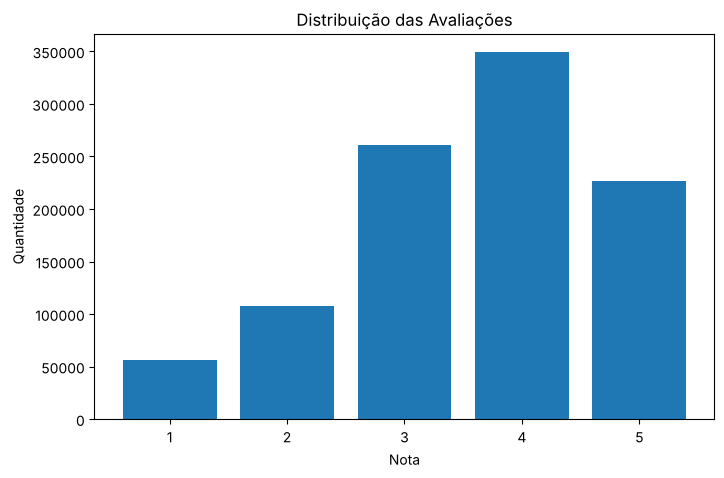

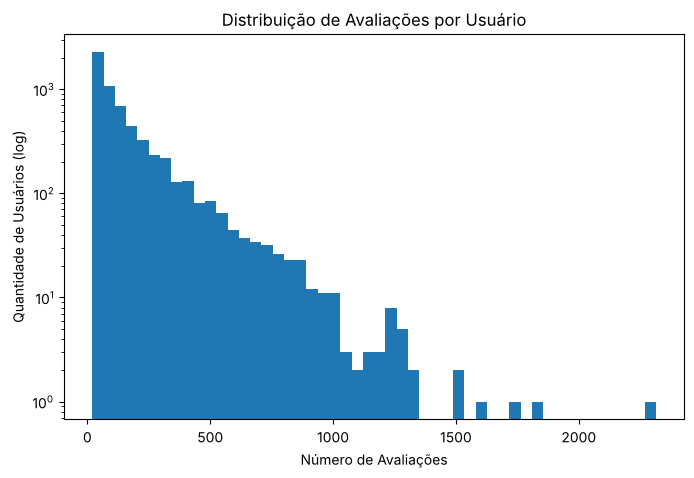

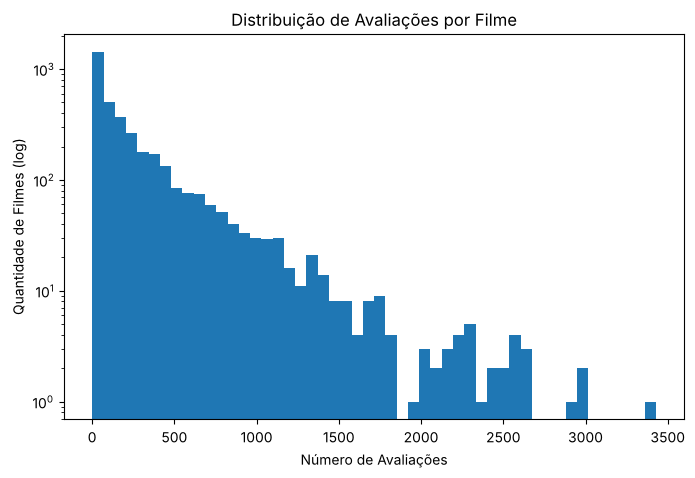

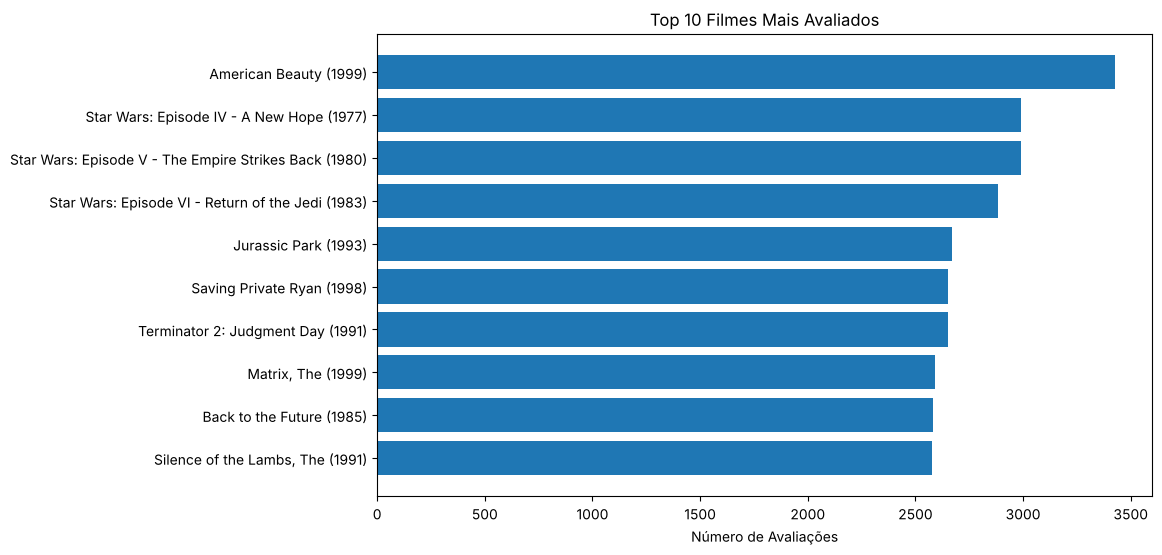

{'Total de usuários': 6040,
 'Total de filmes': 3883,
 'Total de avaliações': 1000209,
 'Média de avaliações por usuário': np.float64(165.6),
 'Média de avaliações por filme': np.float64(269.89)}

In [3]:
import matplotlib.pyplot as plt

# 1. Quantidade de avaliações por nota
rating_counts = ratings['Rating'].value_counts().sort_index()

plt.figure(figsize=(8,5))
plt.bar(rating_counts.index, rating_counts.values)
plt.title('Distribuição das Avaliações')
plt.xlabel('Nota')
plt.ylabel('Quantidade')
plt.xticks(rating_counts.index)
plt.show()

# 2. Número de avaliações por usuário
ratings_per_user = ratings.groupby('UserID').size()

plt.figure(figsize=(8,5))
plt.hist(ratings_per_user, bins=50, log=True)
plt.title('Distribuição de Avaliações por Usuário')
plt.xlabel('Número de Avaliações')
plt.ylabel('Quantidade de Usuários (log)')
plt.show()

# 3. Número de avaliações por filme
ratings_per_movie = ratings.groupby('MovieID').size()

plt.figure(figsize=(8,5))
plt.hist(ratings_per_movie, bins=50, log=True)
plt.title('Distribuição de Avaliações por Filme')
plt.xlabel('Número de Avaliações')
plt.ylabel('Quantidade de Filmes (log)')
plt.show()

# 4. Top 10 filmes mais avaliados
top_movies = ratings_per_movie.sort_values(ascending=False).head(10)
top_movies = top_movies.reset_index().merge(movies, on='MovieID')

plt.figure(figsize=(10,6))
plt.barh(top_movies['Title'], top_movies[0])
plt.xlabel('Número de Avaliações')
plt.title('Top 10 Filmes Mais Avaliados')
plt.gca().invert_yaxis()
plt.show()

# 5. Estatísticas gerais
stats = {
    'Total de usuários': users['UserID'].nunique(),
    'Total de filmes': movies['MovieID'].nunique(),
    'Total de avaliações': ratings.shape[0],
    'Média de avaliações por usuário': round(ratings_per_user.mean(), 2),
    'Média de avaliações por filme': round(ratings_per_movie.mean(), 2)
}

stats


## Análise Exploratória dos Dados MovieLens
###  Estatísticas Gerais
-Total de usuários: 6.040
 
- Total de filmes: 3.883
 
- Total de avaliações: 1.000.209
 
- Média de avaliações por usuário: 165,6
  
- Média de avaliações por filme: 269,89

### Principais Insights dos Gráficos
1. Distribuição das Notas:A maioria das notas está concentrada em 4 e 5, indicando uma tendência dos usuários darem avaliações mais altas.
 
2. Distribuição de Avaliações por Usuário:A maior parte dos usuários avalia poucos filmes, enquanto poucos usuários são altamente ativos.
 
3. Distribuição de Avaliações por Filme:A maioria dos filmes possui poucas avaliações, enquanto poucos filmes são muito populares.
 
4. Top 10 Filmes Mais Avaliados:Os filmes mais populares são aqueles que tendem a ser mais conhecidos no mercado, como American Beauty (1999), Star Wars (1977), entre outros.

## Matriz de Interações

A matriz de interações é uma representação dos dados de avaliações, onde as linhas representam os usuários e as colunas representam os filmes. Cada célula na matriz contém a avaliação que um usuário deu a um filme específico. Essa matriz é útil para análises de filtragem colaborativa e sistemas de recomendação.

In [4]:
from scipy.sparse import csr_matrix

# Construindo a matriz de interações (usuário x filme) usando as avaliações como valores
interaction_matrix = ratings.pivot_table(
    index='UserID',
    columns='MovieID',
    values='Rating'
).fillna(0)

# Converter para formato esparso para otimizar memória
interaction_sparse = csr_matrix(interaction_matrix.values)

# Mostrar a dimensão da matriz
interaction_shape = interaction_matrix.shape

interaction_shape, interaction_matrix.head()


((6040, 3706),
 MovieID  1     2     3     4     5     6     7     8     9     10    ...  \
 UserID                                                               ...   
 1         5.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   
 2         0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   
 3         0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   
 4         0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   
 5         0.0   0.0   0.0   0.0   0.0   2.0   0.0   0.0   0.0   0.0  ...   
 
 MovieID  3943  3944  3945  3946  3947  3948  3949  3950  3951  3952  
 UserID                                                               
 1         0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
 2         0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
 3         0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
 4         0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
 5         0.0   0

## Separação em Treino, Validação e Teste

Antes de qualquer ajuste de hiperparâmetros, as avaliações são separadas em três conjuntos, de forma cronológica **dentro de cada usuário**:

| Conjunto | Conteúdo | Uso |
|---|---|---|
| **Treino** | as avaliações mais antigas (~64%) | ajustar os modelos durante a seleção |
| **Validação** | as ~16% seguintes | escolher hiperparâmetros (fatores do SVD, α, variante de conteúdo…) |
| **Teste** | as ~20% mais recentes | medir o desempenho **uma única vez**, no final |

Treino + validação formam o conjunto de **desenvolvimento**. Depois que tudo é escolhido na validação, os modelos são re-treinados no desenvolvimento e avaliados no teste.

**Regra do notebook:** nenhuma célula usa `test_df` para tomar decisões. Ele só aparece na seção *Avaliação final no teste*.


In [5]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

# ------------------------------------------------------------
# Split cronológico por usuário: treino | validação | teste
# ------------------------------------------------------------
TEST_FRAC = 0.2   # 20% mais recentes de cada usuário -> teste
VAL_FRAC = 0.2    # 20% mais recentes do que sobrou -> validação

def separar_ultimos(df, frac):
    """Separa as `frac` avaliações mais recentes de cada usuário (mínimo 1)."""
    df = df.sort_values(['UserID', 'Timestamp'])
    pos_do_fim = df.groupby('UserID').cumcount(ascending=False)
    n = df.groupby('UserID')['MovieID'].transform('size')
    n_corte = np.maximum(1, np.round(n * frac)).astype(int)
    return df[pos_do_fim >= n_corte], df[pos_do_fim < n_corte]

dev_df, test_df = separar_ultimos(ratings, TEST_FRAC)
train_df, val_df = separar_ultimos(dev_df, VAL_FRAC)

# Índices fixos de usuários e filmes (filmes na mesma ordem de `movies`)
user_ids = np.sort(ratings['UserID'].unique())
item_ids = movies['MovieID'].values
u_idx = pd.Series(np.arange(len(user_ids)), index=user_ids)
i_idx = pd.Series(np.arange(len(item_ids)), index=item_ids)
n_users, n_items = len(user_ids), len(item_ids)

def matriz(df):
    """Matriz esparsa usuário x filme com as notas de `df`."""
    return csr_matrix(
        (df['Rating'].astype(np.float32).values,
         (u_idx[df['UserID']].values, i_idx[df['MovieID']].values)),
        shape=(n_users, n_items))

for nome, d in [('Treino', train_df), ('Validação', val_df), ('Teste', test_df)]:
    print(f"{nome:<10} {len(d):>9,} avaliações ({len(d) / len(ratings):.0%})")


Treino       640,166 avaliações (64%)
Validação    160,027 avaliações (16%)
Teste        200,016 avaliações (20%)


### Limitação: este split é temporal por usuário, não um corte temporal global

Cada usuário tem seu passado no treino e seu futuro no teste. Mas o recorte é feito **usuário a usuário**: o treino pode conter avaliações de *outros* usuários feitas **depois** do momento em que começa o teste de um determinado usuário. Em produção isso não existe, pois o sistema só conhece o que já aconteceu até o instante da recomendação.

Na prática, o modelo pode "ver" tendências futuras (por exemplo, um filme lançado depois que ganhou popularidade). As métricas daqui em diante podem ser **um pouco otimistas** em relação a uma simulação em tempo real. A célula abaixo mede o tamanho dessa exposição.

Para uma simulação fiel de tempo real, a alternativa é um **corte temporal global** (todas as avaliações antes da data *T* no treino, depois de *T* no teste), com a desvantagem de deixar muitos usuários fora do teste ou sem histórico no treino.


In [6]:
# Quanto do conjunto de desenvolvimento é "futuro" para cada usuário de teste?
inicio_teste = test_df.groupby('UserID')['Timestamp'].min()
ts_dev = np.sort(dev_df['Timestamp'].values)
n_futuro = len(ts_dev) - np.searchsorted(ts_dev, inicio_teste.values, side='right')
frac_futuro = n_futuro / len(ts_dev)

print(f"Em média, {frac_futuro.mean():.1%} das avaliações de desenvolvimento são posteriores "
      f"ao início do teste do usuário (mediana {np.median(frac_futuro):.1%}).")
print(f"Usuários com alguma avaliação 'do futuro' no desenvolvimento: {(n_futuro > 0).mean():.0%}")
print(f"Período coberto: {pd.to_datetime(ratings['Timestamp'].min(), unit='s'):%Y-%m-%d} "
      f"a {pd.to_datetime(ratings['Timestamp'].max(), unit='s'):%Y-%m-%d}")


Em média, 47.8% das avaliações de desenvolvimento são posteriores ao início do teste do usuário (mediana 47.0%).
Usuários com alguma avaliação 'do futuro' no desenvolvimento: 100%
Período coberto: 2000-04-25 a 2003-02-28


##  Filtragem Colaborativa

###  Matrix Factorization (SVD/ALS):

 Matrix Factorization (SVD/ALS) é a melhor escolha. Funciona muito bem no MovieLens

In [7]:
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD

# Definir o modelo SVD
svd = TruncatedSVD(n_components=20, random_state=42)
svd_matrix = svd.fit_transform(interaction_sparse)

# Função para gerar recomendações com SVD
def recommend_movies_svd(user_id, n_recommendations=10):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."
    
    user_index = interaction_matrix.index.get_loc(user_id)
    user_vector = svd_matrix[user_index]

    scores = np.dot(svd.components_.T, user_vector)
    movie_ids = interaction_matrix.columns

    recommendations = pd.DataFrame({
        'MovieID': movie_ids,
        'Score': scores
    })

    # Remover filmes que o usuário já assistiu
    movies_watched = interaction_matrix.loc[user_id]
    watched = movies_watched[movies_watched > 0].index
    recommendations = recommendations[~recommendations['MovieID'].isin(watched)]

    # Top N recomendações
    top_recommendations = recommendations.sort_values(by='Score', ascending=False).head(n_recommendations)

    # Obter os títulos dos filmes
    top_recommendations = top_recommendations.merge(movies, on='MovieID')

    return top_recommendations[['Title', 'Genres', 'Score']]

# Testar para usuário 1
svd_recommendations_user1 = recommend_movies_svd(user_id=1, n_recommendations=10)

svd_recommendations_user1

,Title,Genres,Score
0,"Lion King, The (1994)",Animation|Children's|Musical,2.608700
1,"Shawshank Redemption, The (1994)",Drama,2.171291
2,Babe (1995),Children's|Comedy|Drama,2.104139
3,"Silence of the Lambs, The (1991)",Drama|Thriller,1.913071
4,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,1.903917
5,Fantasia (1940),Animation|Children's|Musical,1.735207
6,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,1.591992
7,Peter Pan (1953),Animation|Children's|Fantasy|Musical,1.562925
8,Sleeping Beauty (1959),Animation|Children's|Musical,1.532199
9,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,1.501439


### Ajustar o número de componentes do SVD com interações ocultas

Para medir se o modelo **prevê** notas desconhecidas, as notas avaliadas precisam ficar escondidas durante o ajuste:

1. O SVD é ajustado **só com o treino**. As notas da validação não entram na matriz.
2. Prevemos as notas da validação e calculamos o RMSE sobre elas.
3. Escolhemos o número de componentes com menor RMSE na validação.

Detalhe: com a matriz preenchida com 0, o SVD "aprende" que filmes não vistos têm nota 0 e prevê notas baixas para tudo. Por isso, para prever notas, centralizamos as notas de cada usuário (nota − média do usuário) antes do SVD e somamos a média de volta na previsão.

Os modelos desta etapa usam nomes próprios (`svd_cv`) para não sobrescrever o `svd` de 20 componentes usado por `recommend_movies_svd()`.


In [8]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error

R_tr = matriz(train_df)

# Centraliza as notas observadas de cada usuário (os zeros = "não avaliado" continuam zero)
media_usuario_tr = np.asarray(R_tr.sum(axis=1)).ravel() / np.maximum(1, R_tr.getnnz(axis=1))
R_tr_coo = R_tr.tocoo()
R_tr_centrada = csr_matrix(
    (R_tr_coo.data - media_usuario_tr[R_tr_coo.row], (R_tr_coo.row, R_tr_coo.col)),
    shape=R_tr.shape)

# Notas da validação: escondidas do ajuste, usadas só para medir o erro
lin_val = u_idx[val_df['UserID']].values
col_val = i_idx[val_df['MovieID']].values
notas_val = val_df['Rating'].values

# Referência: prever sempre a média do usuário (equivale a 0 componentes)
rmse_media = np.sqrt(mean_squared_error(notas_val, media_usuario_tr[lin_val]))
resultados_rmse = [{'n_components': 0, 'RMSE validação': rmse_media}]

for n_comp in [10, 20, 50, 100, 200]:
    svd_cv = TruncatedSVD(n_components=n_comp, random_state=42)
    fatores_usuario = svd_cv.fit_transform(R_tr_centrada)
    previsto = media_usuario_tr[lin_val] + np.einsum(
        'ij,ji->i', fatores_usuario[lin_val], svd_cv.components_[:, col_val])
    previsto = np.clip(previsto, 1, 5)
    rmse = np.sqrt(mean_squared_error(notas_val, previsto))
    resultados_rmse.append({'n_components': n_comp, 'RMSE validação': rmse})

results_df = pd.DataFrame(resultados_rmse)
n_comp_rmse = int(results_df.loc[results_df['RMSE validação'].idxmin(), 'n_components'])
print(f"Melhor número de componentes (RMSE na validação): {n_comp_rmse}")
results_df.round(4)


Melhor número de componentes (RMSE na validação): 10


,n_components,RMSE validação
0,0,1.0462
1,10,1.0054
2,20,1.0055
3,50,1.0104
4,100,1.0175
5,200,1.0277


### Conclusão

Com as notas da validação realmente escondidas, o resultado muda bastante em relação à validação antiga:

- O melhor RMSE é com **10 componentes (≈ 1,005)**, apenas um pouco melhor que prever a média de cada usuário (≈ 1,046). Mais componentes **pioram** a previsão (100 componentes: ≈ 1,018), ao contrário do que a reconstrução antiga sugeria.
- O antigo "RMSE 2,18 com 100 componentes" media reconstrução de notas já vistas, por isso sempre melhorava com mais componentes.
- Como previsor de notas, o TruncatedSVD é claramente pior que o SVD do Surprise (RMSE ≈ 0,87 na mesma validação, célula abaixo).

Para **listas de recomendação** o critério é outro: o número de componentes é escolhido pelo NDCG@10 na validação, na seção de avaliação offline. A célula seguinte mantém 100 componentes apenas como demonstração.


In [9]:
# Aplicar SVD otimizado com 100 componentes
svd_optimized = TruncatedSVD(n_components=100, random_state=42)
svd_matrix_optimized = svd_optimized.fit_transform(interaction_sparse)

# Função para gerar recomendações usando o SVD otimizado
def recommend_movies_svd_optimized(user_id, n_recommendations=10):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."
    
    user_index = interaction_matrix.index.get_loc(user_id)
    user_vector = svd_matrix_optimized[user_index]

    scores = np.dot(svd_optimized.components_.T, user_vector)
    movie_ids = interaction_matrix.columns

    recommendations = pd.DataFrame({
        'MovieID': movie_ids,
        'Score': scores
    })

    # Remover filmes que o usuário já assistiu
    movies_watched = interaction_matrix.loc[user_id]
    watched = movies_watched[movies_watched > 0].index
    recommendations = recommendations[~recommendations['MovieID'].isin(watched)]

    # Top N recomendações
    top_recommendations = recommendations.sort_values(by='Score', ascending=False).head(n_recommendations)

    # Obter os títulos dos filmes
    top_recommendations = top_recommendations.merge(movies, on='MovieID')

    return top_recommendations[['Title', 'Genres', 'Score']]

# Gerar recomendações para o usuário 1
svd_optimized_recommendations_user1 = recommend_movies_svd_optimized(user_id=1, n_recommendations=10)
svd_optimized_recommendations_user1

,Title,Genres,Score
0,"Lion King, The (1994)",Animation|Children's|Musical,3.464555
1,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,2.283371
2,Fantasia (1940),Animation|Children's|Musical,2.113384
3,Ghostbusters (1984),Comedy|Horror,1.927834
4,Sleeping Beauty (1959),Animation|Children's|Musical,1.725836
5,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,1.710751
6,Peter Pan (1953),Animation|Children's|Fantasy|Musical,1.705988
7,"Green Mile, The (1999)",Drama|Thriller,1.569269
8,Alice in Wonderland (1951),Animation|Children's|Musical,1.552391
9,Pinocchio (1940),Animation|Children's,1.483890


### Tuning avançado:
O TruncatedSVD (sklearn) possui poucos hiperparâmetros. Para tuning avançado e modelos realmente robustos de fatoração de matrizes, recomendamos utilizar bibliotecas específicas de recomendação como:

 Surprise (SVD, SVD++) → suporte a regularização, taxa de aprendizado, número de épocas (iterations).

### SVD com Surprise

O tuning usa **somente o treino** para ajustar e a **validação** para escolher (menor RMSE). O teste não participa. Depois, o modelo escolhido é re-treinado com todos os dados apenas para as demonstrações de recomendação do usuário 1.

In [11]:
from itertools import product
from joblib import Parallel, delayed
from surprise import Dataset, Reader, SVD, accuracy

reader = Reader(rating_scale=(1, 5))

# Ajuste SÓ no treino e escolha pelo RMSE na validação (o teste não participa)
trainset_tr = Dataset.load_from_df(train_df[['UserID', 'MovieID', 'Rating']], reader).build_full_trainset()
validacao_surprise = list(val_df[['UserID', 'MovieID', 'Rating']].itertuples(index=False, name=None))

param_grid = {
    'n_factors': [50, 100, 150],
    'lr_all': [0.002, 0.005, 0.01],
    'reg_all': [0.02, 0.05, 0.1],
    'n_epochs': [20, 50, 70]
}
combinacoes = [dict(zip(param_grid, v)) for v in product(*param_grid.values())]

def rmse_validacao(params):
    modelo = SVD(**params, random_state=42)
    modelo.fit(trainset_tr)
    return accuracy.rmse(modelo.test(validacao_surprise), verbose=False)

rmses = Parallel(n_jobs=-1)(delayed(rmse_validacao)(p) for p in combinacoes)
busca_surprise = pd.DataFrame(combinacoes).assign(**{'RMSE validação': rmses}) \
                   .sort_values('RMSE validação').reset_index(drop=True)
melhores_params = {k: (int(v) if k in ('n_factors', 'n_epochs') else float(v))
                   for k, v in busca_surprise.iloc[0].drop('RMSE validação').items()}

print(f"Melhores parâmetros (validação): {melhores_params}")
print(f"RMSE na validação: {busca_surprise['RMSE validação'].iloc[0]:.4f}")

# Para as demonstrações a seguir (recomendações do usuário 1), o modelo escolhido
# é re-treinado com TODOS os dados, como seria feito em produção.
data = Dataset.load_from_df(ratings[['UserID', 'MovieID', 'Rating']], reader)
best_model = SVD(**melhores_params, random_state=42)
best_model.fit(data.build_full_trainset())

busca_surprise.head(5).round(4)


Melhores parâmetros (validação): {'n_factors': 150, 'lr_all': 0.01, 'reg_all': 0.1, 'n_epochs': 70}
RMSE na validação: 0.8699


,n_factors,lr_all,reg_all,n_epochs,RMSE validação
0,150,0.01,0.10,70,0.8699
1,100,0.01,0.10,70,0.8703
2,50,0.01,0.10,70,0.8706
3,150,0.01,0.10,50,0.8712
4,150,0.01,0.05,20,0.8713


In [12]:
# Função de recomendação
def recommend_movies_surprise(user_id, n_recommendations=10):
    trainset = data.build_full_trainset()
    all_movie_ids = trainset._raw2inner_id_items.keys()

    user_watched = set([j for (j, _) in trainset.ur[trainset.to_inner_uid(user_id)]])

    predictions = []
    for movie_id in all_movie_ids:
        if trainset.to_inner_iid(movie_id) not in user_watched:
            pred = best_model.predict(user_id, movie_id)
            predictions.append((movie_id, pred.est))

    top_predictions = sorted(predictions, key=lambda x: x[1], reverse=True)[:n_recommendations]
    top_movie_ids = [x[0] for x in top_predictions]

    recommended_movies = movies[movies['MovieID'].isin(top_movie_ids)]
    return recommended_movies

# Exemplo para usuário 1
recommend_movies_surprise(1)


,MovieID,Title,Genres
52,53,Lamerica (1994),Drama
315,318,"Shawshank Redemption, The (1994)",Drama
553,557,Mamma Roma (1962),Drama
589,593,"Silence of the Lambs, The (1991)",Drama|Thriller
777,787,"Gate of Heavenly Peace, The (1995)",Documentary
847,858,"Godfather, The (1972)",Action|Crime|Drama
892,904,Rear Window (1954),Mystery|Thriller
2434,2503,"Apple, The (Sib) (1998)",Drama
3164,3233,Smashing Time (1967),Comedy
3448,3517,"Bells, The (1926)",Crime|Drama


In [13]:
import pandas as pd

# Obter todos os itens
all_items = ratings['MovieID'].unique()

# Itens que o usuário 1 já avaliou
rated_items = ratings[ratings['UserID'] == 1]['MovieID'].values

# Filtrar itens não avaliados
items_to_predict = [iid for iid in all_items if iid not in rated_items]

# Fazer predições
predictions = [best_model.predict(1, iid) for iid in items_to_predict]

# Ordenar pelos maiores ratings previstos
predictions.sort(key=lambda x: x.est, reverse=True)

# Top 10 recomendações
top_10 = predictions[:10]

# Mostrar
for pred in top_10:
    print(f"Filme {pred.iid} - Nota estimada: {pred.est:.2f}")


Filme 2503 - Nota estimada: 4.79
Filme 318 - Nota estimada: 4.76
Filme 53 - Nota estimada: 4.65
Filme 787 - Nota estimada: 4.63
Filme 557 - Nota estimada: 4.62
Filme 904 - Nota estimada: 4.61
Filme 858 - Nota estimada: 4.60
Filme 593 - Nota estimada: 4.58
Filme 3233 - Nota estimada: 4.58
Filme 3517 - Nota estimada: 4.57


##  Filtragem Baseada em Conteúdo (Content-Based Filtering)

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Preparar os dados de gêneros
movies['Genres'] = movies['Genres'].fillna('')

# Vetorização dos gêneros usando TF-IDF
tfidf = TfidfVectorizer(token_pattern=r'[^|]+')
tfidf_matrix = tfidf.fit_transform(movies['Genres'])

# Calcular a similaridade de cosseno entre filmes
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Mapear MovieID para índice na matriz
movie_indices = pd.Series(movies.index, index=movies['MovieID']).drop_duplicates()

# Função para recomendar filmes semelhantes com base no conteúdo
def recommend_content_based(movie_id, n_recommendations=10):
    if movie_id not in movie_indices:
        return f"MovieID {movie_id} não encontrado na base."

    idx = movie_indices[movie_id]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:n_recommendations+1]  # Remove o próprio filme

    movie_indices_list = [i[0] for i in sim_scores]
    similarity_scores = [i[1] for i in sim_scores]

    recommended = movies.iloc[movie_indices_list].copy()
    recommended['Similarity'] = similarity_scores

    return recommended[['MovieID', 'Title', 'Genres', 'Similarity']]

# Testar recomendação para o filme ID 1 (Toy Story)
content_recommendations = recommend_content_based(movie_id=1, n_recommendations=10)

content_recommendations

,MovieID,Title,Genres,Similarity
1050,1064,Aladdin and the King of Thieves (1996),Animation|Children's|Comedy,1.000000
2072,2141,"American Tail, An (1986)",Animation|Children's|Comedy,1.000000
2073,2142,"American Tail: Fievel Goes West, An (1991)",Animation|Children's|Comedy,1.000000
2285,2354,"Rugrats Movie, The (1998)",Animation|Children's|Comedy,1.000000
2286,2355,"Bug's Life, A (1998)",Animation|Children's|Comedy,1.000000
3045,3114,Toy Story 2 (1999),Animation|Children's|Comedy,1.000000
3542,3611,Saludos Amigos (1943),Animation|Children's|Comedy,1.000000
3682,3751,Chicken Run (2000),Animation|Children's|Comedy,1.000000
3685,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Animation|Children's|Comedy,1.000000
12,13,Balto (1995),Animation|Children's,0.938841


Para o filme "Toy Story (1995)", os filmes mais similares são aqueles que compartilham os mesmos gêneros (Animation|Children's|Comedy). Todos obtiveram similaridade máxima (1.0) — o que faz sentido, pois compartilham exatamente os mesmos gêneros.

### recomendações baseadas em conteúdo para um usuário

In [15]:
# Função para gerar recomendações baseadas em conteúdo para um usuário
def recommend_content_for_user(user_id, n_recommendations=10):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."
    
    # Filmes que o usuário assistiu
    user_ratings = interaction_matrix.loc[user_id]
    watched_movies = user_ratings[user_ratings > 0].index.tolist()

    if not watched_movies:
        return f"Usuário {user_id} não avaliou nenhum filme."

    # Somar as similaridades dos filmes assistidos
    movie_idx_list = [movie_indices[movie] for movie in watched_movies if movie in movie_indices]

    user_profile = cosine_sim[movie_idx_list].sum(axis=0)

    # Remover filmes que o usuário já viu
    user_profile[movie_idx_list] = 0

    # Pegar os filmes com maior similaridade
    top_indices = user_profile.argsort()[::-1][:n_recommendations]

    recommended = movies.iloc[top_indices].copy()
    recommended['Similarity_Score'] = user_profile[top_indices]

    return recommended[['MovieID', 'Title', 'Genres', 'Similarity_Score']]

# Gerar recomendações para o usuário 1
user_content_recommendations = recommend_content_for_user(user_id=1, n_recommendations=10)

user_content_recommendations

,MovieID,Title,Genres,Similarity_Score
2009,2078,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,20.345044
2033,2102,Steamboat Willie (1940),Animation|Children's|Comedy|Musical,20.345044
2012,2081,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,20.319142
2011,2080,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance,20.319142
1011,1024,"Three Caballeros, The (1945)",Animation|Children's|Musical,19.062430
2027,2096,Sleeping Beauty (1959),Animation|Children's|Musical,19.062430
2023,2092,"Return of Jafar, The (1993)",Animation|Children's|Musical,19.062430
1019,1032,Alice in Wonderland (1951),Animation|Children's|Musical,19.062430
360,364,"Lion King, The (1994)",Animation|Children's|Musical,19.062430
3090,3159,Fantasia 2000 (1999),Animation|Children's|Musical,19.062430


Observações:
As recomendações são altamente focadas em filmes do mesmo perfil de gênero que o usuário já consome (Animation, Children's, Comedy, Musical).

## Sistema Híbrido

Definição do Sistema Híbrido:
O modelo combina:

  Filtragem Colaborativa (SVD) — baseada no comportamento de usuários (padrões de avaliações).

  Filtragem Baseada em Conteúdo — baseada nas características dos itens (gêneros dos filmes).

Lógica do Sistema Híbrido:

Para cada filme, combinamos:

  Score Colaborativo (SVD) — preferência global dos usuários.

  Score de Conteúdo — similaridade com os interesses do usuário.

A combinação pode ser feita via média ponderada:

Score Final =𝛼⋅Score Colaborativo+(1−𝛼)⋅Score de Conteudo

Onde α (alpha) controla o peso de cada modelo (ex.: 0.5 = pesos iguais).

| α           | Interpretação                                      |
| ----------- | -------------------------------------------------- |
| **α → 1.0** | 🔥 Prioriza 100% **Filtragem Colaborativa (SVD)**  |
| **α → 0.0** | 🔍 Prioriza 100% **Filtragem Baseada em Conteúdo** |
| **0.5**     | ⚖️ Equilíbrio entre Colaborativa e Conteúdo        |


> **Nota:** as funções desta seção são a versão exploratória (SVD com 100 componentes, α escolhido à mão). A configuração definitiva, escolhida na validação e verificada no teste, está na seção **Recomendador final**, no fim do notebook.

In [16]:
# Função para Sistema Híbrido
def recommend_hybrid(user_id, n_recommendations=10, alpha=0.5):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."

    # 🔹 Score colaborativo (SVD)
    user_index = interaction_matrix.index.get_loc(user_id)
    user_vector = svd_matrix_optimized[user_index]
    scores_collab = np.dot(svd_optimized.components_.T, user_vector)
    movie_ids = interaction_matrix.columns

    df_collab = pd.DataFrame({
        'MovieID': movie_ids,
        'Score_Collab': scores_collab
    })

    # Remover filmes já assistidos
    movies_watched = interaction_matrix.loc[user_id]
    watched = movies_watched[movies_watched > 0].index
    df_collab = df_collab[~df_collab['MovieID'].isin(watched)]

    # 🔸 Score baseado em conteúdo
    user_ratings = interaction_matrix.loc[user_id]
    watched_movies = user_ratings[user_ratings > 0].index.tolist()

    if watched_movies:
        pares = [(movie_indices[m], user_ratings[m]) for m in watched_movies if m in movie_indices]
        movie_idx_list = [p[0] for p in pares]
        notas = np.array([p[1] for p in pares])
        # Cada filme visto pesa (nota - média do usuário): filmes de que ele gostou
        # atraem recomendações parecidas, filmes de que não gostou as afastam.
        user_profile = (cosine_sim[movie_idx_list] * (notas - notas.mean())[:, None]).sum(axis=0)
        user_profile[movie_idx_list] = 0  # Zera filmes já assistidos

        df_content = pd.DataFrame({
            'MovieID': movies['MovieID'],
            'Score_Content': user_profile
        })
    else:
        # Se o usuário não assistiu nada, o score de conteúdo é zero
        df_content = pd.DataFrame({
            'MovieID': movies['MovieID'],
            'Score_Content': 0
        })

    # 🔗 Combinar os scores
    hybrid_df = df_collab.merge(df_content, on='MovieID')

    # ⚖️ Normalizar os dois scores para [0, 1] antes de combinar.
    # Sem isso, o conteúdo (soma de similaridades) domina o colaborativo e o α perde efeito.
    for col in ['Score_Collab', 'Score_Content']:
        s = hybrid_df[col]
        hybrid_df[col] = (s - s.min()) / (s.max() - s.min() + 1e-9)

    hybrid_df['Hybrid_Score'] = alpha * hybrid_df['Score_Collab'] + (1 - alpha) * hybrid_df['Score_Content']

    # Top N recomendações
    top_hybrid = hybrid_df.sort_values(by='Hybrid_Score', ascending=False).head(n_recommendations)
    top_hybrid = top_hybrid.merge(movies, on='MovieID')

    return top_hybrid[['MovieID', 'Title', 'Genres', 'Hybrid_Score']]

# Testar para usuário 1
hybrid_recommendations_user1 = recommend_hybrid(user_id=1, n_recommendations=10, alpha=0.5)


hybrid_recommendations_user1

,MovieID,Title,Genres,Hybrid_Score
0,1225,Amadeus (1984),Drama,0.761706
1,953,It's a Wonderful Life (1946),Drama,0.760159
2,1704,Good Will Hunting (1997),Drama,0.733687
3,1682,"Truman Show, The (1998)",Drama,0.730837
4,1957,Chariots of Fire (1981),Drama,0.707521
5,318,"Shawshank Redemption, The (1994)",Drama,0.703751
6,3148,"Cider House Rules, The (1999)",Drama,0.696052
7,1231,"Right Stuff, The (1983)",Drama,0.693307
8,1302,Field of Dreams (1989),Drama,0.692443
9,62,Mr. Holland's Opus (1995),Drama,0.688891


Testar diferentes valores de α na prática:

In [17]:
# Testar diferentes valores de alpha
alphas = [0.2, 0.5, 0.8]

# Guardar resultados para cada alpha
results = []

for alpha in alphas:
    recommendations = recommend_hybrid(user_id=1, n_recommendations=5, alpha=alpha)
    recommendations = recommendations.copy()
    recommendations['Alpha'] = alpha
    results.append(recommendations)

# Concatenar os resultados
final_results = pd.concat(results, ignore_index=True)

final_results

,MovieID,Title,Genres,Hybrid_Score,Alpha
0,1225,Amadeus (1984),Drama,0.904683,0.2
1,953,It's a Wonderful Life (1946),Drama,0.904064,0.2
2,1704,Good Will Hunting (1997),Drama,0.893475,0.2
3,1682,"Truman Show, The (1998)",Drama,0.892335,0.2
4,1957,Chariots of Fire (1981),Drama,0.883008,0.2
5,1225,Amadeus (1984),Drama,0.761706,0.5
6,953,It's a Wonderful Life (1946),Drama,0.760159,0.5
7,1704,Good Will Hunting (1997),Drama,0.733687,0.5
8,1682,"Truman Show, The (1998)",Drama,0.730837,0.5
9,1957,Chariots of Fire (1981),Drama,0.707521,0.5


Observações:
Com α = 0.2, prioriza fortemente o conteúdo (filmes com gêneros similares ao que o usuário já gosta).

Com α = 0.8, prioriza fortemente o comportamento colaborativo (filmes populares entre usuários com perfil semelhante).

Com α = 0.5, busca equilíbrio entre ambos.

## Definir um α  adaptativo por perfil.

### Adaptativo (Inteligente)

- Calculado dinamicamente com base no perfil do usuário:

- Onde a constante controla o peso inicial.

1.      Ex.: constante = 50 → quando um usuário tem poucas avaliações, α fica próximo de 0. (mais Conteúdo).
2.      Quando ultrapassa 50 avaliações, α começa a se aproximar de 1. (mais Colaborativo).

### Fórmula implementada:

In [18]:
def calculate_alpha(user_id, constant=50):
    if user_id not in interaction_matrix.index:
        return 0.5  # fallback

    num_ratings = (interaction_matrix.loc[user_id] > 0).sum()
    alpha = num_ratings / (num_ratings + constant)
    return round(alpha, 2)


Exemplo prático:
Usuário com 5 avaliações → α ≈ 0.09 → Prioriza Conteúdo.

Usuário com 50 avaliações → α ≈ 0.5 → Equilíbrio.

Usuário com 200 avaliações → α ≈ 0.8 → Prioriza Colaborativa.

### cálculo de α adaptativo no pipeline de recomendação

In [19]:
# Função para calcular alpha adaptativo
def calculate_alpha(user_id, constant=50):
    if user_id not in interaction_matrix.index:
        return 0.5  # fallback padrão

    num_ratings = (interaction_matrix.loc[user_id] > 0).sum()
    alpha = num_ratings / (num_ratings + constant)
    return round(alpha, 2)

# Função híbrida com alpha adaptativo embutido
def recommend_hybrid_adaptive(user_id, n_recommendations=10, constant=50):
    if user_id not in interaction_matrix.index:
        return f"UserID {user_id} não encontrado."

    # Calcular alpha adaptativo
    alpha = calculate_alpha(user_id, constant=constant)

    # 🔹 Score colaborativo (SVD)
    user_index = interaction_matrix.index.get_loc(user_id)
    user_vector = svd_matrix_optimized[user_index]
    scores_collab = np.dot(svd_optimized.components_.T, user_vector)
    movie_ids = interaction_matrix.columns

    df_collab = pd.DataFrame({
        'MovieID': movie_ids,
        'Score_Collab': scores_collab
    })

    # Remover filmes já assistidos
    movies_watched = interaction_matrix.loc[user_id]
    watched = movies_watched[movies_watched > 0].index
    df_collab = df_collab[~df_collab['MovieID'].isin(watched)]

    # 🔸 Score baseado em conteúdo
    user_ratings = interaction_matrix.loc[user_id]
    watched_movies = user_ratings[user_ratings > 0].index.tolist()

    if watched_movies:
        pares = [(movie_indices[m], user_ratings[m]) for m in watched_movies if m in movie_indices]
        movie_idx_list = [p[0] for p in pares]
        notas = np.array([p[1] for p in pares])
        # Cada filme visto pesa (nota - média do usuário): filmes de que ele gostou
        # atraem recomendações parecidas, filmes de que não gostou as afastam.
        user_profile = (cosine_sim[movie_idx_list] * (notas - notas.mean())[:, None]).sum(axis=0)
        user_profile[movie_idx_list] = 0  # Zera filmes já assistidos

        df_content = pd.DataFrame({
            'MovieID': movies['MovieID'],
            'Score_Content': user_profile
        })
    else:
        df_content = pd.DataFrame({
            'MovieID': movies['MovieID'],
            'Score_Content': 0
        })

    # 🔗 Combinar os scores
    hybrid_df = df_collab.merge(df_content, on='MovieID')

    # ⚖️ Normalizar os dois scores para [0, 1] antes de combinar.
    # Sem isso, o conteúdo (soma de similaridades) domina o colaborativo e o α perde efeito.
    for col in ['Score_Collab', 'Score_Content']:
        s = hybrid_df[col]
        hybrid_df[col] = (s - s.min()) / (s.max() - s.min() + 1e-9)

    hybrid_df['Hybrid_Score'] = alpha * hybrid_df['Score_Collab'] + (1 - alpha) * hybrid_df['Score_Content']

    # Top N recomendações
    top_hybrid = hybrid_df.sort_values(by='Hybrid_Score', ascending=False).head(n_recommendations)
    top_hybrid = top_hybrid.merge(movies, on='MovieID')
    top_hybrid['Alpha_Used'] = alpha

    return top_hybrid[['MovieID', 'Title', 'Genres', 'Hybrid_Score', 'Alpha_Used']]

# Testar para usuário 1
hybrid_adaptive_recommendations = recommend_hybrid_adaptive(user_id=1, n_recommendations=10, constant=50)

hybrid_adaptive_recommendations

,MovieID,Title,Genres,Hybrid_Score,Alpha_Used
0,1225,Amadeus (1984),Drama,0.756940,0.51
1,953,It's a Wonderful Life (1946),Drama,0.755362,0.51
2,1704,Good Will Hunting (1997),Drama,0.728361,0.51
3,1682,"Truman Show, The (1998)",Drama,0.725453,0.51
4,1957,Chariots of Fire (1981),Drama,0.701671,0.51
5,318,"Shawshank Redemption, The (1994)",Drama,0.697826,0.51
6,3148,"Cider House Rules, The (1999)",Drama,0.689973,0.51
7,1231,"Right Stuff, The (1983)",Drama,0.687173,0.51
8,1302,Field of Dreams (1989),Drama,0.686292,0.51
9,364,"Lion King, The (1994)",Animation|Children's|Musical,0.684802,0.51


Conclusão desse módulo:

✔️ O sistema agora ajusta automaticamente a influência de cada técnica (Conteúdo x Colaborativa) com base no perfil do usuário.

✔️ Usuários novos → Mais Conteúdo.

✔️ Usuários ativos → Mais Colaborativa.

## Avaliação Offline das Recomendações (Top-N)

O RMSE mede se o modelo acerta a **nota** de um filme, mas um sistema de recomendação entrega uma **lista**. Esta seção avalia o que importa: *os 10 filmes recomendados são filmes que o usuário de fato gostou?*

**Protocolo** (usa o split definido no início do notebook):

1. **Fase de validação:** os modelos são ajustados no **treino** e comparados na **validação**. É aqui que escolhemos o número de componentes do SVD, a variante de conteúdo, o α do híbrido e a constante do α adaptativo.
2. **Fase de teste:** com tudo escolhido, os modelos são re-treinados no **desenvolvimento** (treino + validação) e avaliados **uma única vez** no **teste**.
3. **Relevante = nota ≥ 4** no conjunto avaliado. Filmes já vistos no conjunto de ajuste nunca são recomendados.
4. **Baselines** (aleatório e popularidade) para saber se a personalização agrega algo.

O SVD do Surprise usa os hiperparâmetros escolhidos pelo RMSE na validação (célula de tuning do Surprise), sem contato com o teste.

### Métricas

- **Precision@10**: dos 10 filmes recomendados, quantos o usuário realmente gostou.
- **Recall@10**: dos filmes que ele gostou, quantos apareceram no top-10.
- **NDCG@10**: como o Precision, mas acertos no topo da lista valem mais. É a métrica usada para as escolhas.
- **Cobertura**: % do catálogo que aparece em pelo menos uma lista.


In [20]:
# ------------------------------------------------------------
# Funções de avaliação (servem tanto para a validação quanto para o teste)
# ------------------------------------------------------------
K = 10
LIMIAR_RELEVANTE = 4
DESCONTO = 1 / np.log2(np.arange(2, K + 2))   # pesos de posição do NDCG

def relevantes_de(df):
    """Para cada usuário (índice de linha), os filmes (índices de coluna) com nota >= limiar."""
    rel = df[df['Rating'] >= LIMIAR_RELEVANTE]
    return (rel.assign(u=u_idx[rel['UserID']].values, i=i_idx[rel['MovieID']].values)
               .groupby('u')['i'].apply(np.array))

def vistos_de(R):
    """Máscara densa (usuários x filmes) do que já foi avaliado na matriz R."""
    return R.toarray() > 0

def top_k(scores, vistos, k=K):
    """Índices dos k filmes de maior score por usuário, ignorando os já vistos."""
    s = np.array(scores, dtype=np.float32, copy=True)
    s[vistos] = -np.inf
    s[np.isnan(s)] = -np.inf
    top = np.argpartition(-s, k, axis=1)[:, :k]
    linhas = np.arange(s.shape[0])[:, None]
    return top[linhas, np.argsort(-s[linhas, top], axis=1)]

def avaliar(scores, nome, vistos, relevantes):
    """Precision@K, Recall@K, NDCG@K e cobertura de catálogo."""
    top = top_k(scores, vistos)
    precs, recs, ndcgs = [], [], []
    for u, rel in relevantes.items():
        acertos = np.isin(top[u], rel)
        precs.append(acertos.sum() / K)
        recs.append(acertos.sum() / len(rel))
        ndcgs.append((acertos * DESCONTO).sum() / DESCONTO[:min(len(rel), K)].sum())
    return {'Modelo': nome,
            f'Precision@{K}': np.mean(precs),
            f'Recall@{K}': np.mean(recs),
            f'NDCG@{K}': np.mean(ndcgs),
            'Cobertura': len(np.unique(top[relevantes.index.values])) / n_items}


### Modelos

Cada modelo é uma função que recebe os dados de ajuste e devolve uma matriz de scores. As mesmas funções são usadas na validação, no teste e no recomendador final, garantindo que o que vai para produção é exatamente o que foi avaliado.

In [21]:
# ------------------------------------------------------------
# Modelos como funções: recebem os dados de ajuste e devolvem uma
# matriz de scores (usuários x filmes). As MESMAS funções são usadas
# na validação, no teste e no recomendador final.
# ------------------------------------------------------------
from sklearn.decomposition import TruncatedSVD
from surprise import Dataset, Reader, SVD

def score_aleatorio(R, seed=42):
    return np.random.default_rng(seed).random(R.shape, dtype=np.float32)

def score_popularidade(R):
    """Quantos usuários avaliaram cada filme (igual para todos os usuários)."""
    pop = np.asarray((R > 0).sum(axis=0)).ravel().astype(np.float32)
    return np.tile(pop, (R.shape[0], 1))

def score_svd_sklearn(R, n_components):
    """TruncatedSVD sobre a matriz de notas (0 = não avaliado), como no notebook."""
    modelo = TruncatedSVD(n_components=n_components, random_state=42)
    fatores = modelo.fit_transform(R)
    return (fatores @ modelo.components_).astype(np.float32)

def score_surprise(df, params):
    """Nota prevista pelo SVD do Surprise para todos os pares usuário x filme."""
    ts = Dataset.load_from_df(df[['UserID', 'MovieID', 'Rating']],
                              Reader(rating_scale=(1, 5))).build_full_trainset()
    m = SVD(**params, random_state=42)
    m.fit(ts)
    # Montamos a matriz direto dos fatores: média + viés usuário + viés filme + p_u · q_i
    P = np.zeros((n_users, params['n_factors']), np.float32); bu = np.zeros(n_users, np.float32)
    Q = np.zeros((n_items, params['n_factors']), np.float32); bi = np.zeros(n_items, np.float32)
    for raw_uid in df['UserID'].unique():
        inner = ts.to_inner_uid(raw_uid)
        P[u_idx[raw_uid]], bu[u_idx[raw_uid]] = m.pu[inner], m.bu[inner]
    for inner in ts.all_items():
        j = i_idx[ts.to_raw_iid(inner)]
        Q[j], bi[j] = m.qi[inner], m.bi[inner]
    return ts.global_mean + bu[:, None] + bi[None, :] + P @ Q.T

def score_conteudo(R, ponderado):
    """Perfil do usuário = soma das similaridades (gêneros) com os filmes que ele viu.
    ponderado=True: cada filme pesa (nota - média do usuário), então filmes de que
    ele não gostou passam a afastar recomendações parecidas."""
    if not ponderado:
        pesos = (R > 0).astype(np.float32)
    else:
        coo = R.tocoo()
        media = np.asarray(R.sum(axis=1)).ravel() / np.maximum(1, R.getnnz(axis=1))
        pesos = csr_matrix((coo.data - media[coo.row], (coo.row, coo.col)), shape=R.shape)
    return np.asarray(pesos @ cosine_sim, dtype=np.float32)

def minmax_por_usuario(scores, vistos):
    """Normaliza os scores de cada usuário para [0, 1], considerando só os filmes não vistos."""
    s = np.array(scores, dtype=np.float32, copy=True)
    s[vistos] = np.nan
    mn = np.nanmin(s, axis=1, keepdims=True)
    mx = np.nanmax(s, axis=1, keepdims=True)
    return (s - mn) / (mx - mn + 1e-9)

def alpha_adaptativo(R, c):
    """α_u = n_u / (n_u + c): mais avaliações -> mais peso no colaborativo."""
    n = R.getnnz(axis=1)
    return (n / (n + c)).astype(np.float32)[:, None]

def combinar(colab, conteudo, R, vistos, alpha=None, c=None, normalizar=True):
    """Combina os dois scores. Use `alpha` (fixo) OU `c` (α adaptativo)."""
    if normalizar:
        colab, conteudo = minmax_por_usuario(colab, vistos), minmax_por_usuario(conteudo, vistos)
    a = alpha_adaptativo(R, c) if c is not None else alpha
    return a * colab + (1 - a) * conteudo

def score_hibrido(R, config):
    """Híbrido completo a partir de uma configuração (dict) escolhida na validação."""
    vistos = vistos_de(R)
    colab = score_svd_sklearn(R, config['n_components'])
    conteudo = score_conteudo(R, ponderado=config['conteudo_ponderado'])
    return combinar(colab, conteudo, R, vistos,
                    alpha=config.get('alpha'), c=config.get('c'))


### Fase de validação: modelos individuais

Aqui escolhemos o número de componentes do SVD pela métrica de ranking (NDCG@10), não pelo RMSE.

In [22]:
# ------------------------------------------------------------
# FASE DE VALIDAÇÃO — ajuste no treino, comparação na validação
# ------------------------------------------------------------
R_tr = matriz(train_df)
vistos_tr = vistos_de(R_tr)
rel_val = relevantes_de(val_df)
print(f"Usuários com ao menos 1 filme relevante na validação: {len(rel_val):,}")

validacao = [
    avaliar(score_aleatorio(R_tr), 'Aleatório', vistos_tr, rel_val),
    avaliar(score_popularidade(R_tr), 'Popularidade', vistos_tr, rel_val),
]

# Número de componentes do SVD sklearn, escolhido pela métrica de ranking
colab_val = {}
for k_comp in [20, 50, 100, 150, 200]:
    colab_val[k_comp] = score_svd_sklearn(R_tr, k_comp)
    validacao.append(avaliar(colab_val[k_comp], f'SVD sklearn ({k_comp} comp.)', vistos_tr, rel_val))

# Variantes de conteúdo
conteudo_val = {p: score_conteudo(R_tr, ponderado=p) for p in (False, True)}
validacao.append(avaliar(conteudo_val[False], 'Conteúdo (original)', vistos_tr, rel_val))
validacao.append(avaliar(conteudo_val[True], 'Conteúdo (ponderado por nota)', vistos_tr, rel_val))

tabela_val = pd.DataFrame(validacao)
svd_val = tabela_val[tabela_val['Modelo'].str.startswith('SVD sklearn')]
n_comp_top = int(svd_val.loc[svd_val[f'NDCG@{K}'].idxmax(), 'Modelo'].split('(')[1].split()[0])
print(f"Componentes escolhidos para o SVD sklearn (NDCG@{K} na validação): {n_comp_top}")
tabela_val.round(4)


Usuários com ao menos 1 filme relevante na validação: 5,944


Componentes escolhidos para o SVD sklearn (NDCG@10 na validação): 20


,Modelo,Precision@10,Recall@10,NDCG@10,Cobertura
0,Aleatório,0.0038,0.0025,0.0042,1.0000
1,Popularidade,0.0676,0.0520,0.0796,0.0252
2,SVD sklearn (20 comp.),0.0801,0.0882,0.1027,0.1617
3,SVD sklearn (50 comp.),0.0761,0.0905,0.0984,0.2163
4,SVD sklearn (100 comp.),0.0714,0.0891,0.0941,0.2640
5,SVD sklearn (150 comp.),0.0663,0.0835,0.0883,0.2933
6,SVD sklearn (200 comp.),0.0615,0.0783,0.0838,0.3235
7,Conteúdo (original),0.0102,0.0115,0.0130,0.7819
8,Conteúdo (ponderado por nota),0.0108,0.0088,0.0125,0.9122


### Fase de validação: híbrido

Testamos α fixo de 0 a 1 e o α adaptativo `n / (n + c)` com várias constantes `c`, para as duas variantes de conteúdo.

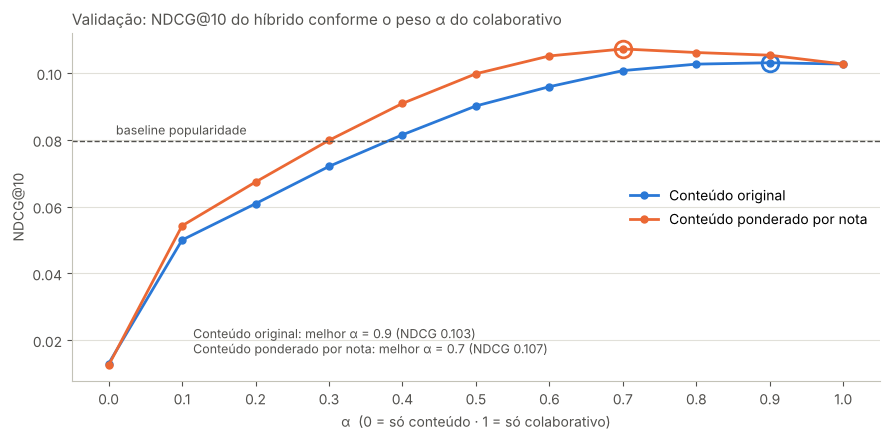

Modelo,Conteúdo original,Conteúdo ponderado por nota
c,,
5.0,0.1049,0.1046
10.0,0.1045,0.1045
15.0,0.1031,0.1025
25.0,0.0991,0.0989
50.0,0.0899,0.0917
100.0,0.0786,0.0835


In [23]:
# ------------------------------------------------------------
# Híbrido na validação: α fixo de 0 a 1 e α adaptativo com várias constantes c
# ------------------------------------------------------------
import matplotlib.pyplot as plt

colab = colab_val[n_comp_top]
nomes_conteudo = {False: 'Conteúdo original', True: 'Conteúdo ponderado por nota'}

busca_hibrido = []
for ponderado, nome in nomes_conteudo.items():
    for a in np.round(np.arange(0, 1.01, 0.1), 1):
        r = avaliar(combinar(colab, conteudo_val[ponderado], R_tr, vistos_tr, alpha=a),
                    nome, vistos_tr, rel_val)
        busca_hibrido.append({**r, 'tipo': 'fixo', 'alpha': a, 'c': None, 'ponderado': ponderado})
    for c in [5, 10, 15, 25, 50, 100]:
        r = avaliar(combinar(colab, conteudo_val[ponderado], R_tr, vistos_tr, c=c),
                    nome, vistos_tr, rel_val)
        busca_hibrido.append({**r, 'tipo': 'adaptativo', 'alpha': None, 'c': c, 'ponderado': ponderado})
busca_hibrido = pd.DataFrame(busca_hibrido)

# Gráfico: α fixo na validação
AZUL, LARANJA, CINZA, TEXTO, EIXO = '#2a78d6', '#eb6834', '#b4b2a9', '#52514e', '#c3c2b7'
fig, ax = plt.subplots(figsize=(9, 4.5))
resumo = []
for ponderado, cor in [(False, AZUL), (True, LARANJA)]:
    d = busca_hibrido[(busca_hibrido['tipo'] == 'fixo') & (busca_hibrido['ponderado'] == ponderado)]
    ax.plot(d['alpha'], d[f'NDCG@{K}'], color=cor, linewidth=2, marker='o', markersize=5,
            label=nomes_conteudo[ponderado])
    melhor = d.loc[d[f'NDCG@{K}'].idxmax()]
    ax.plot(melhor['alpha'], melhor[f'NDCG@{K}'], 'o', markersize=12,
            markerfacecolor='none', markeredgecolor=cor, markeredgewidth=2)
    resumo.append(f"{nomes_conteudo[ponderado]}: melhor α = {melhor['alpha']:.1f} "
                  f"(NDCG {melhor[f'NDCG@{K}']:.3f})")
pop_val = tabela_val.loc[tabela_val['Modelo'] == 'Popularidade', f'NDCG@{K}'].item()
ax.axhline(pop_val, color=TEXTO, linestyle='--', linewidth=1)
ax.text(0.01, pop_val + 0.002, 'baseline popularidade', fontsize=9, color=TEXTO)
ax.text(0.15, 0.08, '\n'.join(resumo), transform=ax.transAxes, fontsize=9, color=TEXTO)
ax.set_title(f'Validação: NDCG@{K} do híbrido conforme o peso α do colaborativo',
             loc='left', fontsize=11, color=TEXTO)
ax.set_xlabel('α  (0 = só conteúdo · 1 = só colaborativo)', color=TEXTO)
ax.set_ylabel(f'NDCG@{K}', color=TEXTO)
ax.set_xticks(np.round(np.arange(0, 1.01, 0.1), 1))
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
for lado in ['left', 'bottom']:
    ax.spines[lado].set_color(EIXO)
ax.tick_params(colors=TEXTO)
ax.grid(axis='y', color='#e1e0d9', linewidth=0.8)
ax.legend(frameon=False, loc='center right')
plt.tight_layout()
plt.show()

# α adaptativo: NDCG por constante c
busca_hibrido[busca_hibrido['tipo'] == 'adaptativo'] \
    .pivot(index='c', columns='Modelo', values=f'NDCG@{K}').round(4)


### Configuração escolhida

In [24]:
# ------------------------------------------------------------
# Escolha da configuração final — feita SÓ com a validação
# ------------------------------------------------------------
melhor = busca_hibrido.loc[busca_hibrido[f'NDCG@{K}'].idxmax()]
config_final = {
    'n_components': n_comp_top,
    'conteudo_ponderado': bool(melhor['ponderado']),
    'alpha': None if melhor['tipo'] == 'adaptativo' else float(melhor['alpha']),
    'c': None if melhor['tipo'] == 'fixo' else int(melhor['c']),
}
ndcg_val_escolhido = melhor[f'NDCG@{K}']
ndcg_val_svd = svd_val[f'NDCG@{K}'].max()

print("Configuração escolhida na validação:")
for chave, valor in config_final.items():
    print(f"  {chave:<20} {valor}")
print(f"\nNDCG@{K} na validação: híbrido {ndcg_val_escolhido:.4f} | SVD sklearn sozinho {ndcg_val_svd:.4f}")


Configuração escolhida na validação:
  n_components         20
  conteudo_ponderado   True
  alpha                0.7
  c                    None

NDCG@10 na validação: híbrido 0.1073 | SVD sklearn sozinho 0.1027


## Avaliação final no teste

Modelos re-treinados no desenvolvimento (treino + validação) e avaliados **uma única vez** no teste. Esta é a estimativa de desempenho a reportar.

Usuários com ao menos 1 filme relevante no teste: 5,966


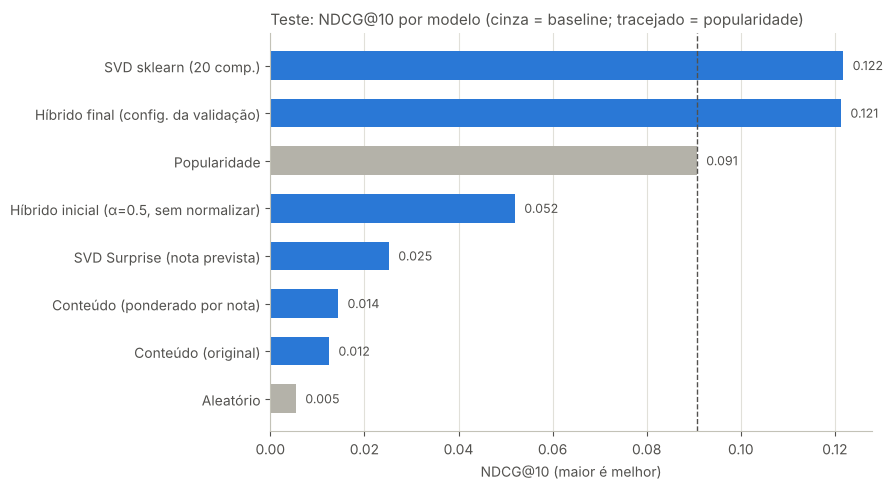

,Modelo,Precision@10,Recall@10,NDCG@10,Cobertura
0,SVD sklearn (20 comp.),0.0992,0.0847,0.1218,0.1774
1,Híbrido final (config. da validação),0.0997,0.0844,0.1213,0.2189
2,Popularidade,0.0798,0.0472,0.0907,0.0301
3,"Híbrido inicial (α=0.5, sem normalizar)",0.0381,0.0400,0.0520,0.4569
4,SVD Surprise (nota prevista),0.0243,0.0168,0.0252,0.0860
5,Conteúdo (ponderado por nota),0.0122,0.0095,0.0144,0.9191
6,Conteúdo (original),0.0098,0.0101,0.0125,0.7744
7,Aleatório,0.0051,0.0029,0.0054,1.0000


In [25]:
# ------------------------------------------------------------
# FASE DE TESTE — re-treino no desenvolvimento (treino + validação),
# avaliação ÚNICA no teste. Nenhuma escolha é feita aqui.
# ------------------------------------------------------------
R_dev = matriz(dev_df)
vistos_dev = vistos_de(R_dev)
rel_teste = relevantes_de(test_df)
print(f"Usuários com ao menos 1 filme relevante no teste: {len(rel_teste):,}")

colab_dev_100 = score_svd_sklearn(R_dev, 100)
conteudo_dev_original = score_conteudo(R_dev, ponderado=False)
scores_hibrido_teste = score_hibrido(R_dev, config_final)

teste = [
    avaliar(score_aleatorio(R_dev), 'Aleatório', vistos_dev, rel_teste),
    avaliar(score_popularidade(R_dev), 'Popularidade', vistos_dev, rel_teste),
    avaliar(score_svd_sklearn(R_dev, n_comp_top), f'SVD sklearn ({n_comp_top} comp.)', vistos_dev, rel_teste),
    avaliar(score_surprise(dev_df, melhores_params), 'SVD Surprise (nota prevista)', vistos_dev, rel_teste),
    avaliar(conteudo_dev_original, 'Conteúdo (original)', vistos_dev, rel_teste),
    avaliar(score_conteudo(R_dev, ponderado=True), 'Conteúdo (ponderado por nota)', vistos_dev, rel_teste),
    # Versão inicial do notebook, para referência: 100 comp., conteúdo original, sem normalizar
    avaliar(combinar(colab_dev_100, conteudo_dev_original, R_dev, vistos_dev, alpha=0.5, normalizar=False),
            'Híbrido inicial (α=0.5, sem normalizar)', vistos_dev, rel_teste),
    avaliar(scores_hibrido_teste, 'Híbrido final (config. da validação)', vistos_dev, rel_teste),
]
tabela_teste = pd.DataFrame(teste).sort_values(f'NDCG@{K}', ascending=False).reset_index(drop=True)

dados = tabela_teste.sort_values(f'NDCG@{K}')
cores = [CINZA if m in ('Aleatório', 'Popularidade') else AZUL for m in dados['Modelo']]
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(dados['Modelo'], dados[f'NDCG@{K}'], color=cores, height=0.6)
ax.axvline(tabela_teste.loc[tabela_teste['Modelo'] == 'Popularidade', f'NDCG@{K}'].item(),
           color=TEXTO, linestyle='--', linewidth=1)
for b in barras:
    ax.text(b.get_width() + 0.002, b.get_y() + b.get_height() / 2,
            f'{b.get_width():.3f}', va='center', fontsize=9, color=TEXTO)
ax.set_title(f'Teste: NDCG@{K} por modelo (cinza = baseline; tracejado = popularidade)',
             loc='left', fontsize=11, color=TEXTO)
ax.set_xlabel(f'NDCG@{K} (maior é melhor)', color=TEXTO)
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
for lado in ['left', 'bottom']:
    ax.spines[lado].set_color(EIXO)
ax.tick_params(colors=TEXTO)
ax.grid(axis='x', color='#e1e0d9', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

tabela_teste.round(4)


## Recomendador final

`criar_recomendador()` usa a configuração escolhida na validação e as mesmas funções da avaliação. A célula verifica que, ajustado no desenvolvimento, ele gera exatamente as listas avaliadas no teste; depois cria a versão de produção com todos os dados.

In [26]:
# ------------------------------------------------------------
# RECOMENDADOR FINAL — a configuração vencedora, usando as mesmas funções da avaliação
# ------------------------------------------------------------
def criar_recomendador(df, config):
    """Ajusta o híbrido em `df` e devolve uma função recomendar(user_id, n)."""
    R = matriz(df)
    vistos = vistos_de(R)
    scores = score_hibrido(R, config)

    def recomendar(user_id, n=10):
        if user_id not in u_idx.index:
            return f"UserID {user_id} não encontrado."
        u = u_idx[user_id]
        # mesma rotina de top-K da avaliação (já exclui os filmes vistos)
        top = top_k(scores[u:u + 1], vistos[u:u + 1], k=n)[0]
        rec = movies.iloc[top][['MovieID', 'Title', 'Genres']].copy()
        rec['Score'] = scores[u, top]
        return rec.reset_index(drop=True)

    return recomendar

# Verificação de consistência: o recomendador ajustado no desenvolvimento precisa
# devolver exatamente as listas que foram avaliadas no teste.
recomendar_dev = criar_recomendador(dev_df, config_final)
top_avaliado = top_k(scores_hibrido_teste, vistos_dev)
divergencias = sum(
    not np.array_equal(i_idx[recomendar_dev(uid)['MovieID']].values, top_avaliado[u_idx[uid]])
    for uid in user_ids
)
print(f"Usuários com lista diferente da avaliada: {divergencias} de {n_users}")
assert divergencias == 0, "O recomendador final não corresponde à configuração avaliada!"

# Versão de produção: mesma configuração, ajustada com TODAS as avaliações
recomendar = criar_recomendador(ratings, config_final)
recomendar(1)


Usuários com lista diferente da avaliada: 0 de 6040


,MovieID,Title,Genres,Score
0,318,"Shawshank Redemption, The (1994)",Drama,0.876331
1,364,"Lion King, The (1994)",Animation|Children's|Musical,0.807021
2,34,Babe (1995),Children's|Comedy|Drama,0.752195
3,1225,Amadeus (1984),Drama,0.708167
4,593,"Silence of the Lambs, The (1991)",Drama|Thriller,0.703288
5,1704,Good Will Hunting (1997),Drama,0.703195
6,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,0.638210
7,1282,Fantasia (1940),Animation|Children's|Musical,0.619919
8,953,It's a Wonderful Life (1946),Drama,0.616898
9,1302,Field of Dreams (1989),Drama,0.616377


## Conclusões

**1. Resultado a reportar (teste, avaliado uma única vez).** O híbrido final (SVD sklearn com 20 componentes + conteúdo ponderado por nota, α = 0,7, scores normalizados) obteve **NDCG@10 = 0,121**, contra **0,091** da popularidade, com cobertura de **22%** do catálogo contra 3%.

**2. O ganho do híbrido não se confirmou no teste.** Na validação, ele superava o SVD sozinho (0,107 contra 0,103). No teste, os dois empatam (**0,121 contra 0,122**). A diferença vista na validação era, em boa parte, efeito de escolher α no mesmo conjunto em que se mede. É exatamente o otimismo que a separação validação/teste existe para revelar. O NDCG de 0,109 da versão anterior deste notebook, com α escolhido no teste, não deve ser usado. A vantagem do híbrido que se manteve é a **cobertura maior** (22% contra 18%): ele recomenda um catálogo mais variado com a mesma precisão.

**3. A normalização continua indispensável.** O híbrido inicial, sem normalizar, fica em **0,052**, abaixo da popularidade.

**4. Bom RMSE ≠ boa lista.** O SVD do Surprise tem o melhor RMSE do notebook (≈ 0,87 na validação), mas é o pior colaborativo no top-10 (**0,025**). Ele é treinado para acertar notas apenas dos filmes que o usuário escolheu ver, e por isso favorece filmes pouco conhecidos com nota prevista alta (Cremonesi et al., 2010).

**5. Menos componentes funcionam melhor no top-N.** Na validação, o NDCG cai de 0,103 (20 componentes) para 0,084 (200 componentes), enquanto a cobertura sobe. Há um trade-off entre precisão e variedade.

**6. O α adaptativo não superou o α fixo na validação.** O melhor `c` foi 5 (NDCG 0,105), que dá α ≈ 0,92 para o usuário típico — ou seja, o adaptativo vira quase "só colaborativo": no MovieLens-1M todo usuário tem 20+ avaliações, então o cenário de "usuário novo" que justifica o α adaptativo praticamente não aparece.

**7. Limitação do split.** O corte é temporal **por usuário**, não global: em média **48%** das avaliações de desenvolvimento são posteriores ao início do teste de cada usuário. Os números acima podem ser otimistas em relação a recomendações em tempo real.

**Próximos passos:**
- repetir a avaliação com um corte temporal global;
- enriquecer o conteúdo (ano do filme, tags) para que ele contribua de fato no híbrido;
- testar a significância da diferença entre híbrido e SVD (por exemplo, bootstrap por usuário).
